# 2 · Skills versus safety

**Question.** Do the skills installed in post-training erode like refusal does?

**Skills**, measured from generated text and checked automatically (greedy decoding): **instruction following**
(IFEval prompts restricted to exactly checkable instructions; prompt-level), **tool calling** (exact tool and
arguments; the basic set used here is at ceiling for 2B), **maths** (GSM8K final answer), **chart reading**
(ChartQA, image input, 5% numeric tolerance). *SE* is the binomial standard error of the starting score.

**Regime:** the gentle 1M-token regime of notebook 1, at 2B (Kaggle) and 0.8B (laptop).

In [1]:
import sys, os; sys.path.insert(0, ".")
import numpy as np, pandas as pd
from kwm import *
setup(); pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
runs = {"2B · code": load("erosion/D3_erosion_Qwen3.5-2B_code_gentle.json"),
        "2B · chat-like": load("erosion/D3_erosion_Qwen3.5-2B_chat_gentle.json"),
        "0.8B · code": load("erosion/D4_skills_Qwen3.5-0.8B_code_gentle.json"),
        "0.8B · chat-like": load("erosion/D4_skills_Qwen3.5-0.8B_chat_gentle.json")}
rows = []
for name, R in runs.items():
    sb = R[0]["skills_baseline"]
    for r in R:
        if not r.get("skills"): continue
        for s in SKILLS:
            rows.append({"run": name, "tokens": r["tokens"], "skill": s.split("_")[0], "start": round(sb[s], 3),
                         "now": round(r["skills"][s], 3), "change, pts": round(100 * (r["skills"][s] - sb[s]), 1),
                         "±1 SE, pts": round(100 * sb[SE_KEY[s]], 1), "wrapped refusal kept": round(r["kept_text_wrap"], 3)})
S = pd.DataFrame(rows); S

,run,tokens,skill,start,now,"change, pts","±1 SE, pts",wrapped refusal kept
0,2B · code,512000,instruction,0.688,0.688,0.0,5.2,0.974
1,2B · code,512000,maths,0.333,0.333,0.0,6.1,0.974
2,2B · code,512000,tools,1.000,1.000,0.0,0.0,0.974
3,2B · code,512000,charts,0.683,0.683,0.0,6.0,0.974
4,2B · code,1003520,instruction,0.688,0.675,-1.2,5.2,0.977
5,2B · code,1003520,maths,0.333,0.433,10.0,6.1,0.977
6,2B · code,1003520,tools,1.000,1.000,0.0,0.0,0.977
7,2B · code,1003520,charts,0.683,0.667,-1.7,6.0,0.977
8,2B · chat-like,512000,instruction,0.688,0.675,-1.2,5.2,0.934
9,2B · chat-like,512000,maths,0.333,0.367,3.3,6.1,0.934


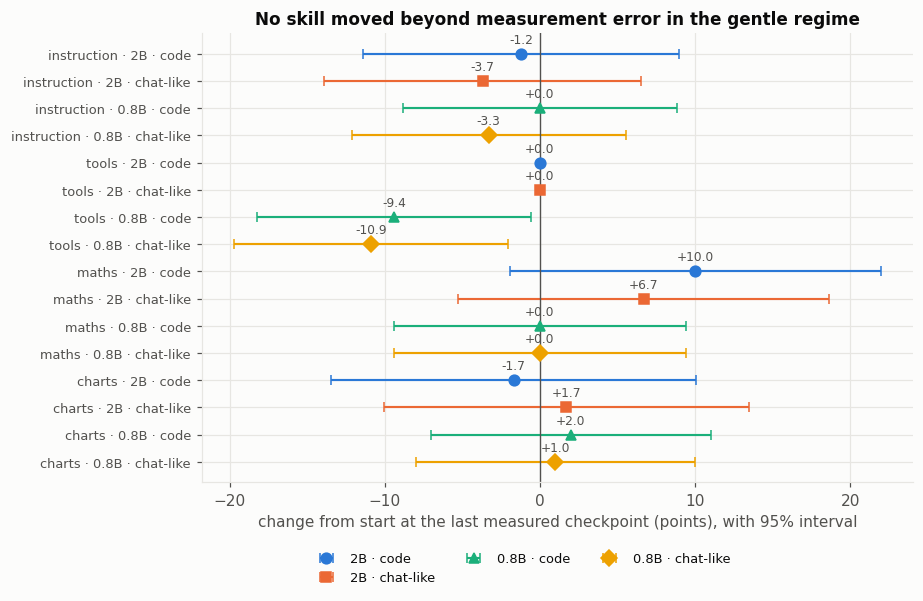

In [2]:
last = S.sort_values("tokens").groupby(["run", "skill"]).tail(1)
style = {"2B · code": (BLUE, "o"), "2B · chat-like": (ORANGE, "s"), "0.8B · code": (AQUA, "^"), "0.8B · chat-like": (YELLOW, "D")}
fig, ax = plt.subplots(figsize=(8.5, 5.6)); labels = []
for skill in ("instruction", "tools", "maths", "charts"):
    for run, (col, mk) in style.items():
        row = last[(last.run == run) & (last.skill == skill)]
        if row.empty: continue
        v, se = row["change, pts"].iloc[0], row["±1 SE, pts"].iloc[0]
        ax.errorbar(v, len(labels), xerr=1.96 * se, fmt=mk, color=col, ecolor=col, elinewidth=1.4, capsize=3, markersize=7,
                    label=run if skill == "instruction" else None)
        ax.annotate(f"{v:+.1f}", (v, len(labels)), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8, color=INK2)
        labels.append(f"{skill} · {run}")
ax.axvline(0, color=INK2, lw=0.9); ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8.5); ax.invert_yaxis()
ax.set_xlabel("change from start at the last measured checkpoint (points), with 95% interval")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.13), ncol=3, fontsize=8.5); ax.set_title("No skill moved beyond measurement error in the gentle regime")
fig.tight_layout(); plt.show()

## What this shows
- In the gentle regime, **no skill moved beyond measurement error at 2B**, while refusal eroded (wrapped −2.3% code,
  −7.6% chat-like). At 0.8B, only tool calling moved (−9 to −11 points, ~2 SE, in both arms); the other three stayed flat. Maths rose in both 2B arms (+10 and +6.7 points; 1.6 and 1.1 SE) — the same direction twice, neither significant.
- This is an **ordering** result — safety erodes *before* skills — not evidence that skills are robust. Thomson's
  far stronger continual pre-training does degrade skills, which is why it needs merging (THESIS_LOG entry 20).
- Tool calling (basic set) is at ceiling for 2B; the realistic-strength notebook uses a harder set.